# Eddy kinetic energy variability from 30 years of altimetry in the Mediterranean Sea
## Reproducing the figures of Hargous, Combes, Barceló-Llull and Pascual (2026)

*Ocean Science* **22**, 549–564 — <https://os.copernicus.org/articles/22/549/2026/>

This notebook rebuilds Figures 1–8 and Table 1 of the paper from the processed
EKE files. It relies on two modules located in `code/`:

| module | content |
|---|---|
| `eke_analysis.py` | region masks, area-weighted series, Yue–Wang trends, satellite-count correction, gridded trends, along-track L3/L4 trends, eddy-atlas statistics |
| `eke_figures.py` | one plotting function per figure |

**Products**

| key | product | grid |
|---|---|---|
| `AM` | `all-sat-euro` (CMEMS DUACS L4, 7 satellites) | 1/8° |
| `AG` | `all-sat-glo` | 1/4° |
| `TG` | `two-sat-glo` (fixed two-satellite constellation) | 1/4° |

**Input data**

* `processed_data/{MED,GLO}/…/NEKE_*_vDT2021_19930101_20230607.nc` — EKE (cm² s⁻²) computed from geostrophic velocity anomalies **relative to the 1993–2023 mean** (`NEKE`), dimensions `(time, lat, lon)`. The CMEMS-reference `EKE_*` files are only needed for the second half of Table 1.
* `data/satellites.npy` — dictionary `{mission: (start_date, end_date)}` of the altimeter active periods.
* `data/20days/*.nc` — 20 days of ground tracks per mission (1–20 May 2022), variables `lon`, `lat`.
* `data/eur_L3_008_061/…` and the L4 products — along-track L3 and gridded L4 data (Fig. 7).
* `data/eddy_aviso/META3.2_DT_{allsat,twosat}/` — META3.2 DT eddy atlas (Fig. 8).

**Run time.** The gridded trend maps (Fig. 6, Table 1) and the along-track trends (Fig. 7) are slow; their results are cached in `results/paper_cache/` and re-used on the next run. Delete the cache to recompute.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

sys.path.append('..')  # the notebook is run from code/notebooks/
import eke_analysis as ea
import eke_figures as ef

plt.rcParams['figure.dpi'] = 100

/home/hargous/anaconda3/envs/paul_eke/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
# ----------------------------- configuration -----------------------------
ROOT = Path(os.environ.get('EKE_ROOT', '../..'))   # project root
DATA = Path('/media/hargous/MyPassport/Med_Global_EKE/data')   # raw data (external drive)
MASK_DIR = ROOT / 'results' / 'masks'               # pre-computed region masks
PROC = ROOT / 'processed_data'
CACHE = ROOT / 'results' / 'paper_cache'            # expensive intermediate results
FIG_DIR = ROOT / 'figures' / 'paper_reproduction'   # output figures
for d in (CACHE, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

VERSION = 'vDT2021'
PERIOD = '19930101_20230607'
NEKE_FILES = {   # EKE from anomalies w.r.t. the 1993-2023 mean
    'AM': PROC / 'MED/ALL_SAT'  / f'NEKE_ALL_SAT_MED_C3S_{VERSION}_{PERIOD}.nc',
    'AG': PROC / 'GLO/ALL_SAT'  / f'NEKE_ALL_SAT_GLO_C3S_{VERSION}_{PERIOD}.nc',
    'TG': PROC / 'GLO/TWO_SAT'  / f'NEKE_TWO_SAT_GLO_C3S_{VERSION}_{PERIOD}.nc',
}
EKE_FILES = {    # CMEMS-reference EKE (1993-2012 climatology), only for the 2nd half of Table 1
    'AM': PROC / 'MED/ALL_SAT'  / f'EKE_ALL_SAT_MED_C3S_{VERSION}_{PERIOD}.nc',
    'AG': PROC / 'GLO/ALL_SAT'  / f'EKE_ALL_SAT_GLO_C3S_{VERSION}_{PERIOD}.nc',
    'TG': PROC / 'GLO/TWO_SAT'  / f'EKE_TWO_SAT_GLO_C3S_{VERSION}_{PERIOD}.nc',
}
N_JOBS = 1                  # parallel workers for the gridded trends (each needs ~0.5 GB)
COMPUTE_CMEMS_TABLE = False # also compute the CMEMS-reference half of Table 1 (adds 3 more trend maps)

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches='tight')

### Load the EKE fields and the region masks

Regions (Fig. 1 and 3): the whole Mediterranean Sea, the Alboran Sea, the eastern Alboran Sea (edge of the Alboran gyre) and the Ierapetra area (isoline of 200 cm² s⁻² of the 30-year mean EKE of `all-sat-euro`). The boolean masks were computed beforehand and are loaded from `results/masks/` (`2mask_{MED,ALB,ALBB,IERAISO}_{MED,GLO}.npy`), one per region and grid.

In [3]:
neke = {k: xr.open_dataset(f)['EKE'] for k, f in NEKE_FILES.items()}   # lazy
grid = {'med': neke['AM'], 'glo': neke['AG']}                          # lat/lon of each grid

mean_eke_am = neke['AM'].mean('time', skipna=False).load()            # 30-year mean EKE, all-sat-euro
masks = ea.load_region_masks(MASK_DIR, grid['med'], grid['glo'])
{r: {g: int(m.sum()) for g, m in v.items()} for r, v in masks.items()}   # number of cells per region

{'MED': {'med': 30658, 'glo': 7664},
 'ALB': {'med': 694, 'glo': 178},
 'ALBB': {'med': 275, 'glo': 69},
 'IERA': {'med': 155, 'glo': 39}}

## Figure 1 — Mean EKE in the Mediterranean Sea (1993–2023, all-sat-euro)

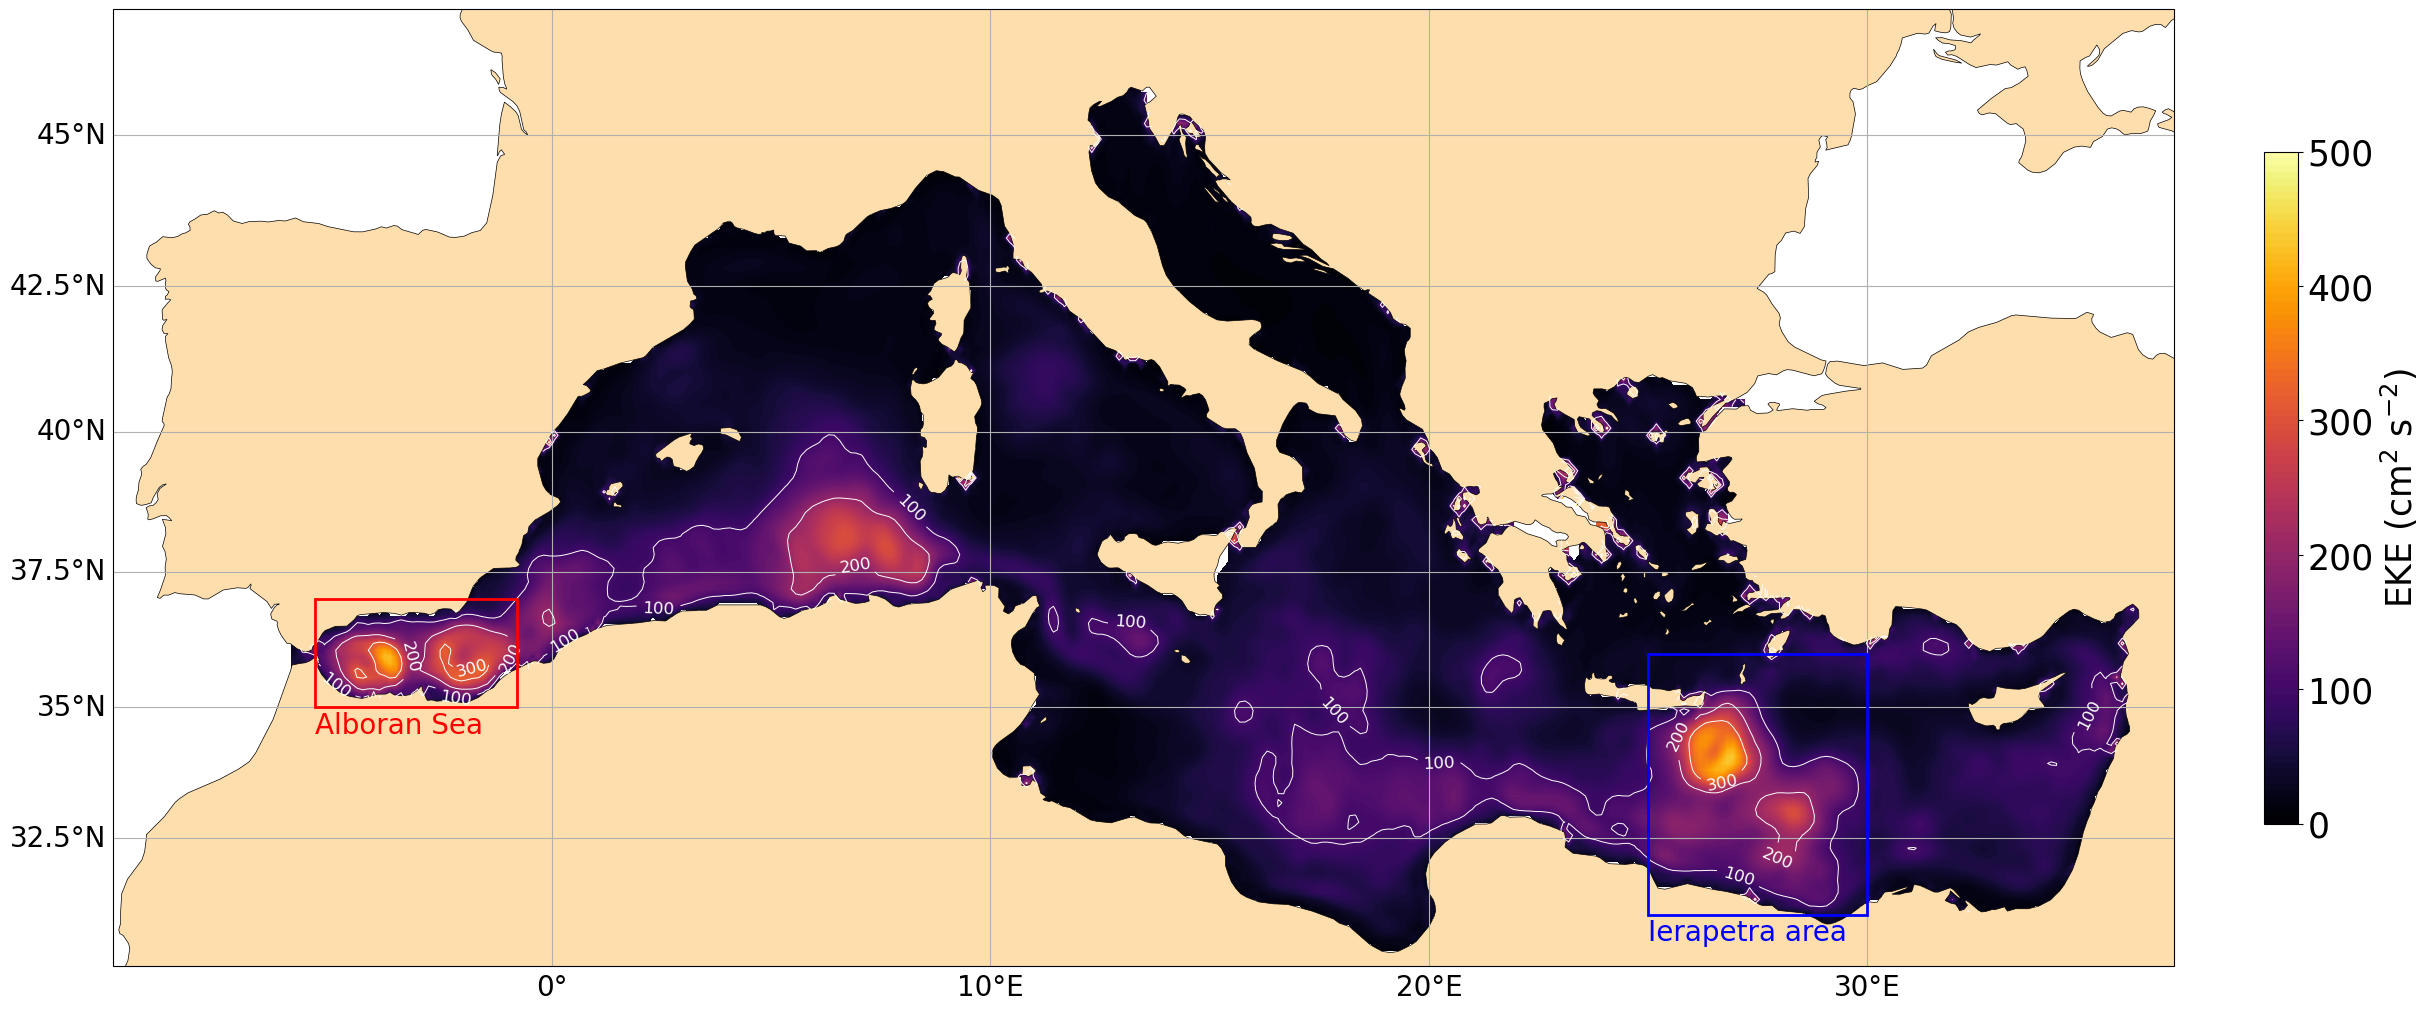

In [4]:
fig = ef.fig1_mean_eke(mean_eke_am.where(masks['MED']['med']))
save(fig, 'fig01.png'); plt.show()

## Figure 2 — Ground tracks and number of altimeters

The number of altimeters is built from the mission periods in `data/satellites.npy`; it is held at 7 after 1 January 2023.

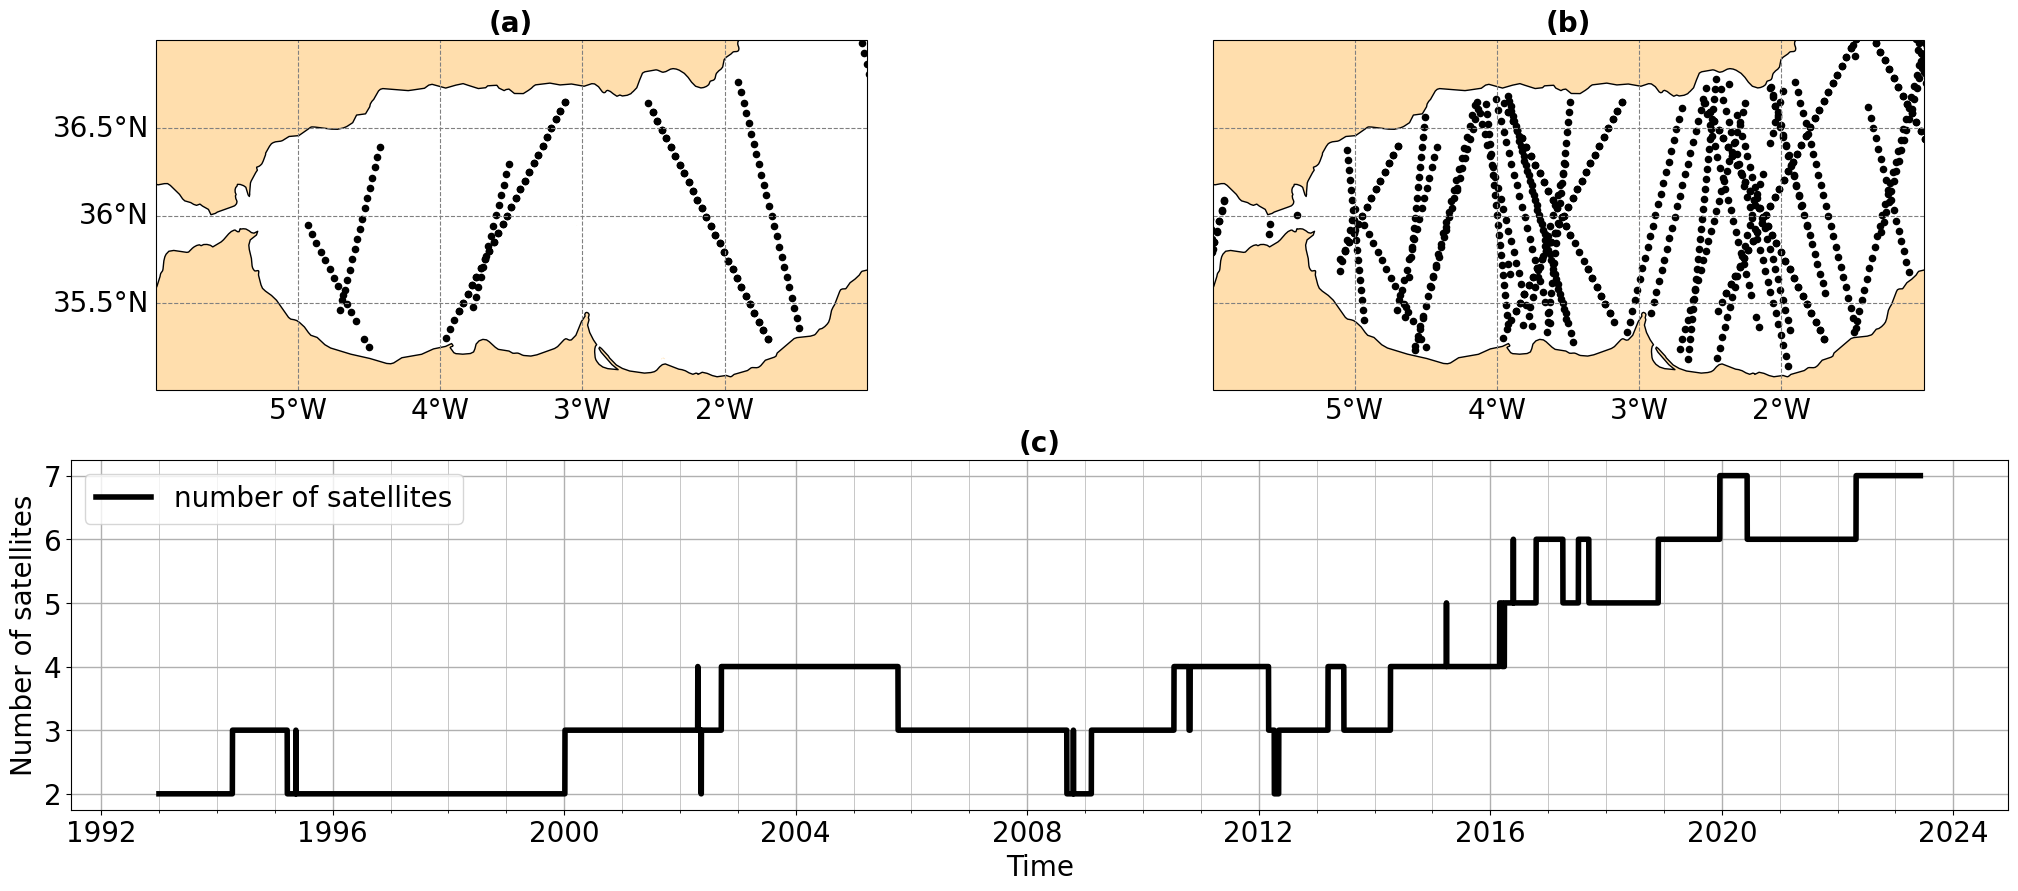

In [5]:
missions = np.load(DATA / 'satellites.npy', allow_pickle=True).item()
n_sat = ea.satellite_timeline(missions, start='1993-01-01', end='2023-06-07')

def read_tracks(name):
    ds = xr.open_dataset(DATA / '20days' / f'{name}.nc')
    lon = ds['lon'].values
    return np.where(lon > 180, lon - 360, lon), ds['lat'].values

all_missions = ['alg', 'c2n', 'h2b', 'j3n', 's3a', 's3b', 's6a']   # 7 satellites, 1-20 May 2022
two_missions = ['s3a', 's6a']                                      # two-sat-glo constellation
tracks = {m: read_tracks(m) for m in all_missions}

fig = ef.fig2_tracks_and_satellites([tracks[m] for m in two_missions],
                                    [tracks[m] for m in all_missions], n_sat)
save(fig, 'fig02.png'); plt.show()

## Figure 3 — Regional EKE time series and trends

Area-weighted mean EKE (cell areas from the haversine formula). Trends are Theil–Sen slopes tested with the Yue and Wang (2004) modified Mann–Kendall test, which accounts for autocorrelation; the standard error uses the effective sample size. Hatched bars / italic numbers are not significant at the 5 % level.

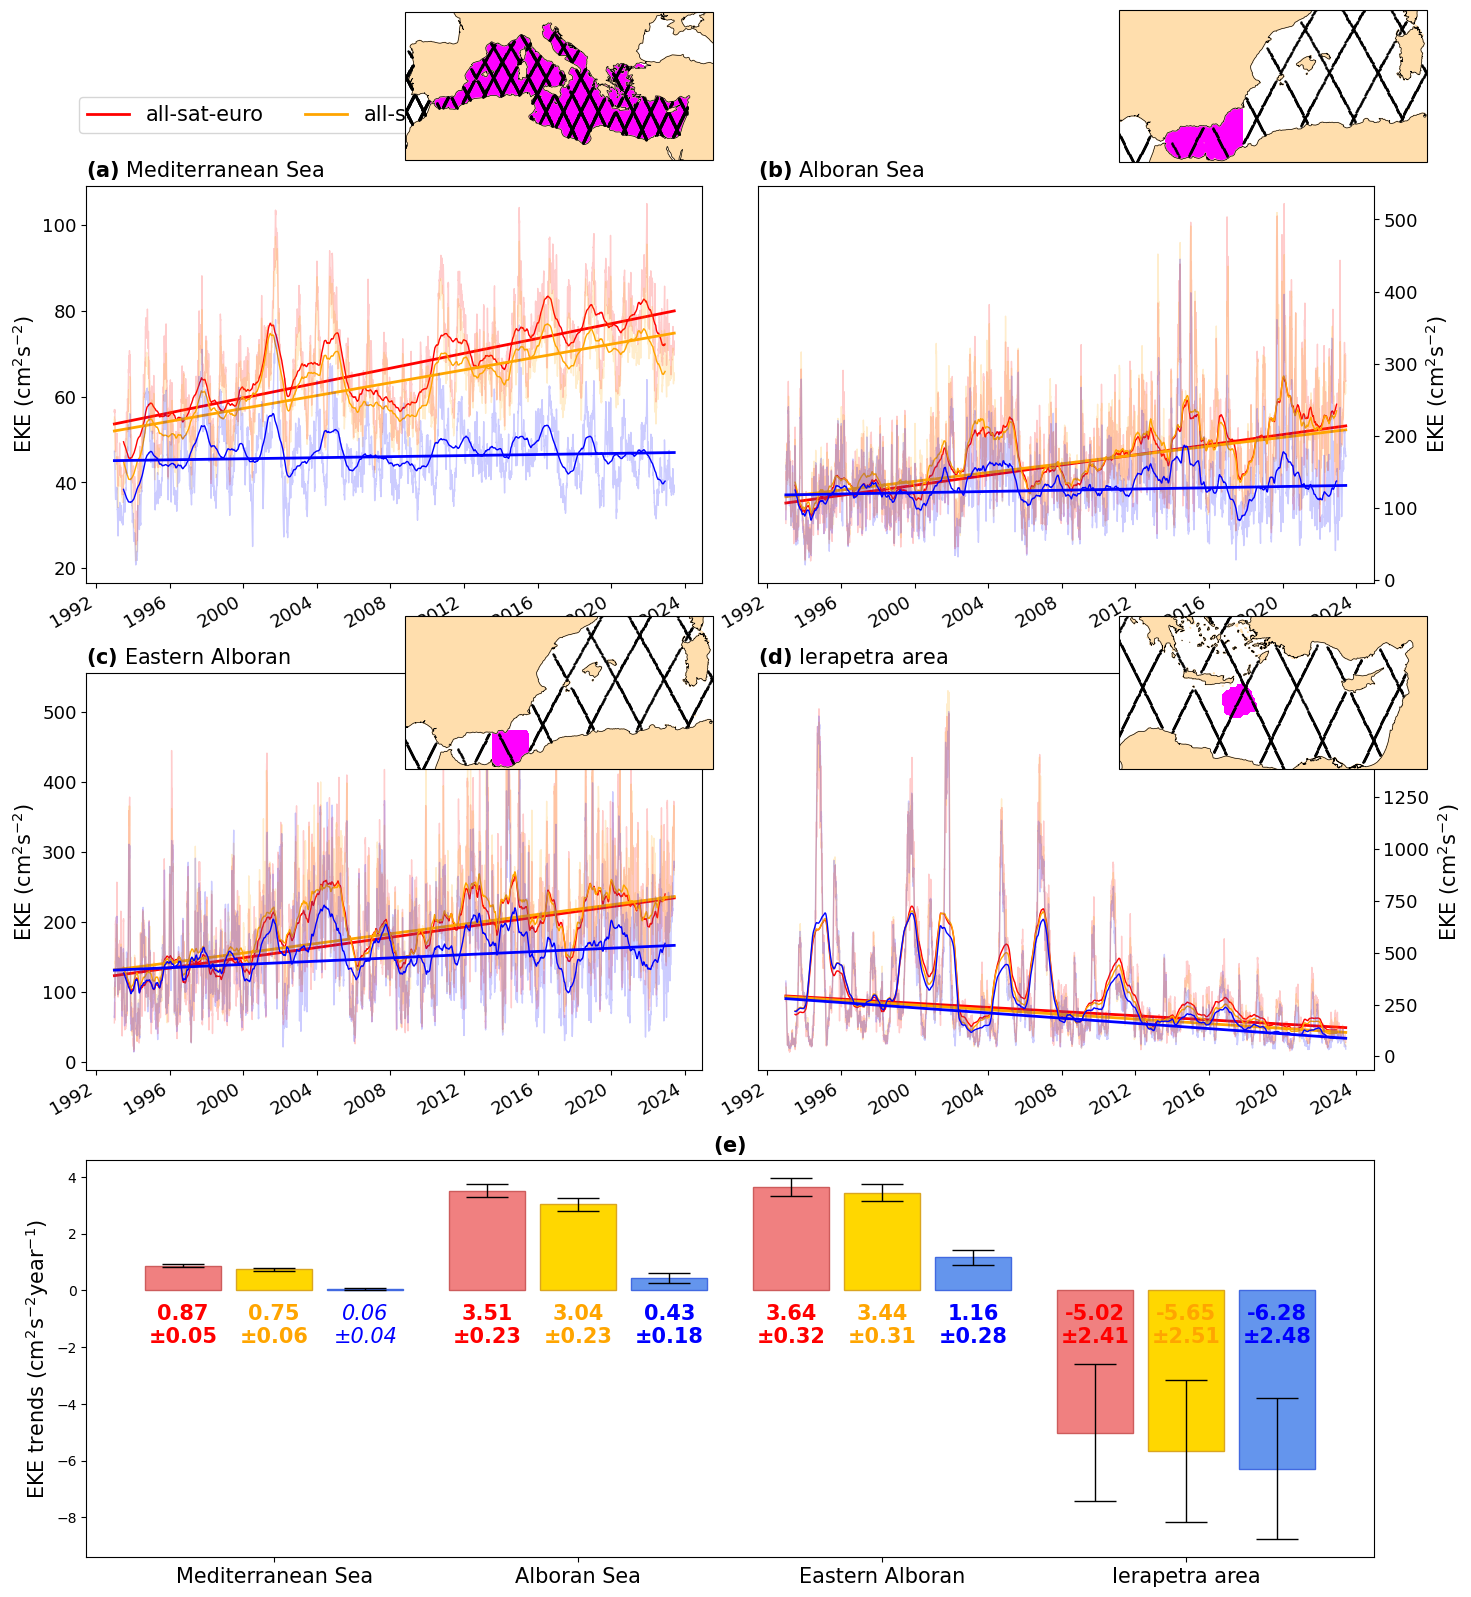

,all-sat-euro,all-sat-glo,two-sat-glo
MED,0.87 ± 0.05 (p=0),0.75 ± 0.06 (p=0),0.06 ± 0.04 (p=0.12)
ALB,3.51 ± 0.23 (p=0),3.04 ± 0.23 (p=0),0.43 ± 0.18 (p=0.0119)
ALBB,3.64 ± 0.32 (p=0),3.44 ± 0.31 (p=0),1.16 ± 0.28 (p=1.44e-05)
IERA,-5.02 ± 2.41 (p=6.93e-05),-5.65 ± 2.51 (p=4.46e-06),-6.28 ± 2.48 (p=1.43e-07)


In [6]:
series = ea.regional_series(neke, masks)   # {region: {product: daily area-weighted mean}}
trends = {r: {p: ea.compute_trend(s.values) for p, s in d.items()} for r, d in series.items()}

# Reference-altimeter tracks shown in the insets (Sentinel-6A; Black Sea and Atlantic removed)
lon6, lat6 = tracks['s6a']
bad = ((lon6 >= 27) & (lat6 >= 40)) | ((lon6 <= 0) & (lat6 >= 42.5))
ref_tracks = (np.where(bad, np.nan, lon6), np.where(bad, np.nan, lat6))

fig = ef.fig3_regional_series(series, trends, masks, grid, ref_tracks)
save(fig, 'fig03.png'); plt.show()

pd.DataFrame({r: {ef.PRODUCTS[p][0]: f'{t.slope:.2f} ± {t.std:.2f} (p={t.p:.3g})' for p, t in d.items()}
              for r, d in trends.items()}).T

## Figure 4 — Effect of the number of satellites

The difference `all-sat-glo − two-sat-glo` follows the number of altimeters. A degree-2 polynomial of the number of satellites is fitted to this difference and subtracted from `all-sat-glo` (`all-sat-glo-corrected`).

correlation (all-sat − two-sat, number of satellites): 0.85
trend of all-sat-glo-corrected: 0.12 ± 0.05 cm2 s-2 yr-1 (p=0.02)


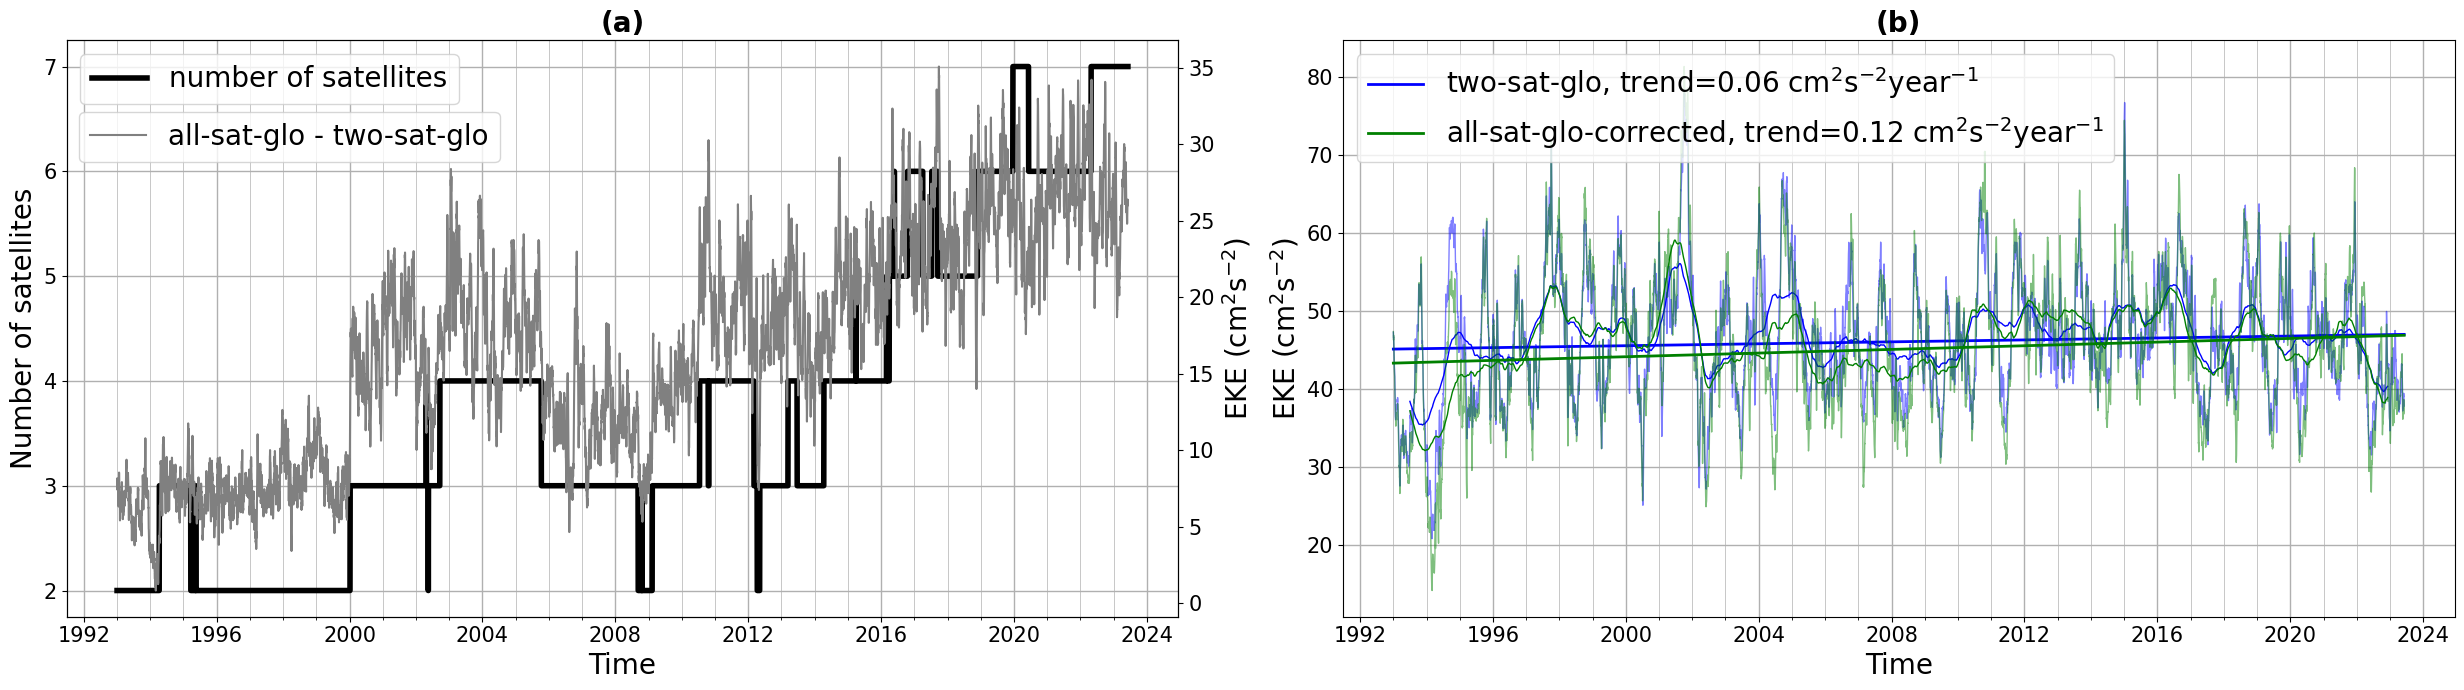

In [7]:
time = series['MED']['TG'].time
# As in the original analysis, the daily satellite timeline (1993-01-01 -> 2023-06-07) is matched
# to the EKE time axis by position, so the two must have the same number of days.
assert len(n_sat) == time.size, f'satellite timeline ({len(n_sat)} days) and EKE time axis ({time.size}) differ'
n_sat = pd.Series(n_sat.values, index=pd.DatetimeIndex(time.values))   # same dates as the EKE fields
nsat_t = n_sat

mean_ag = ea.unweighted_masked_mean(neke['AG'], masks['MED']['glo']).values
mean_tg = ea.unweighted_masked_mean(neke['TG'], masks['MED']['glo']).values
corrected_values, coef = ea.correct_for_satellite_count(mean_ag, mean_tg, nsat_t.values, degree=2)
corrected = xr.DataArray(corrected_values, dims='time', coords={'time': time.values})
trend_corrected = ea.compute_trend(corrected_values)

diff = series['MED']['AG'] - series['MED']['TG']
print(f'correlation (all-sat − two-sat, number of satellites): {np.corrcoef(diff, nsat_t)[0, 1]:.2f}')
print(f"trend of all-sat-glo-corrected: {trend_corrected.slope:.2f} ± {trend_corrected.std:.2f} cm2 s-2 yr-1 (p={trend_corrected.p:.3g})")

fig = ef.fig4_satellite_correction(time, n_sat, diff, series['MED']['TG'], corrected,
                                   trends['MED']['TG'], trend_corrected)
save(fig, 'fig04.png'); plt.show()

## Figure 5 — Spatial correlation between the EKE difference and the number of satellites

At each grid point, Pearson correlation between the one-year running mean of `all-sat-glo − two-sat-glo` and the one-year running mean of the number of satellites. Cells with a non-significant correlation (p > 0.05) are shown in black.

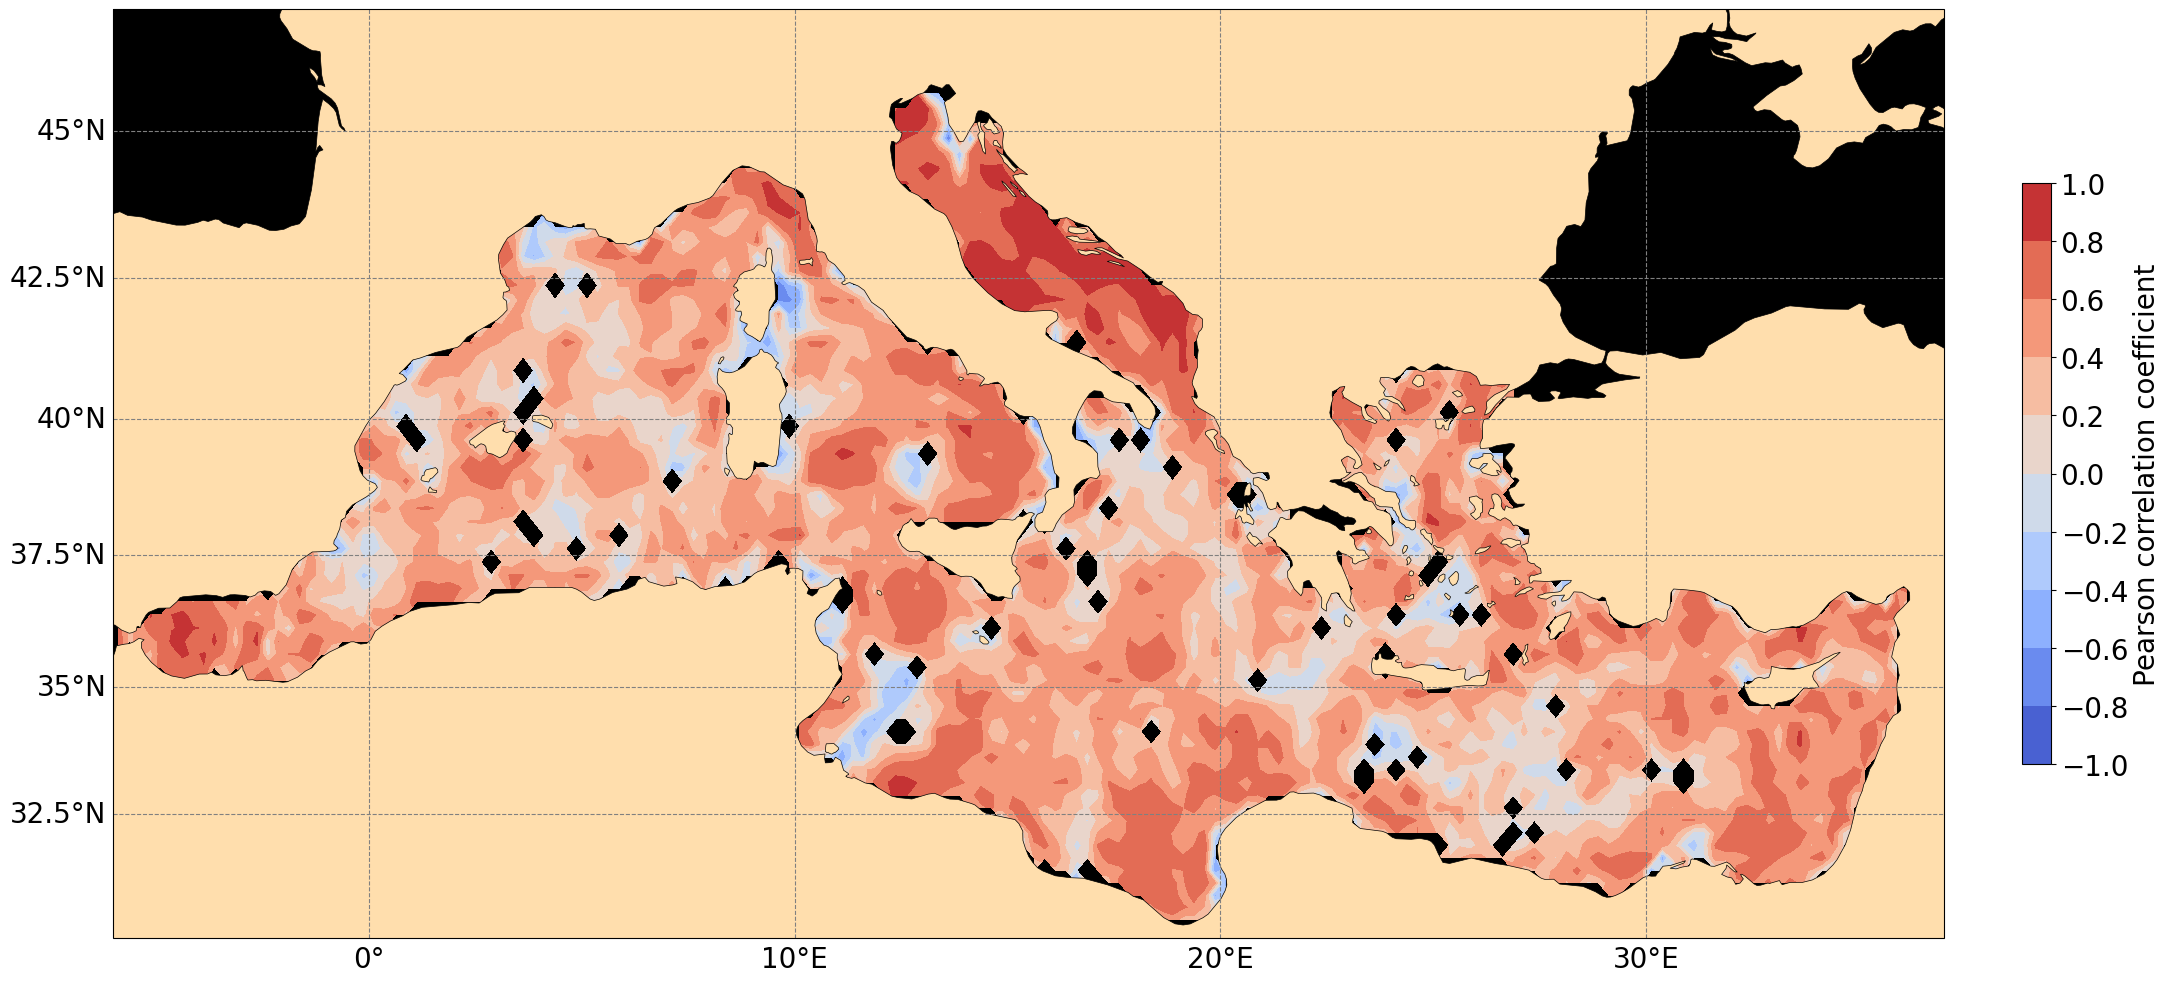

In [8]:
amt = (neke['AG'] - neke['TG']).load()
amt_roll = amt.rolling(time=365, center=True).mean()
nsat_roll = n_sat.rolling('365D', center=True).mean().reindex(pd.DatetimeIndex(amt.time.values))

r, p = ea.pearson_map(nsat_roll.values, amt_roll.transpose('time', 'lat', 'lon').values)
r = np.where(masks['MED']['glo'] & (p <= ea.ALPHA), r, np.nan)

fig = ef.fig5_correlation_map(amt.lon.values, amt.lat.values, r)
save(fig, 'fig05.png'); plt.show()

## Figure 6 — EKE trend maps

Yue–Wang trend at every grid point (**very slow**: a few seconds per grid point, i.e. about 1 h at 1/4° and several hours at 1/8°; use `N_JOBS` to parallelise. Cached afterwards). Hatching marks non-significant trends (p > 0.05).

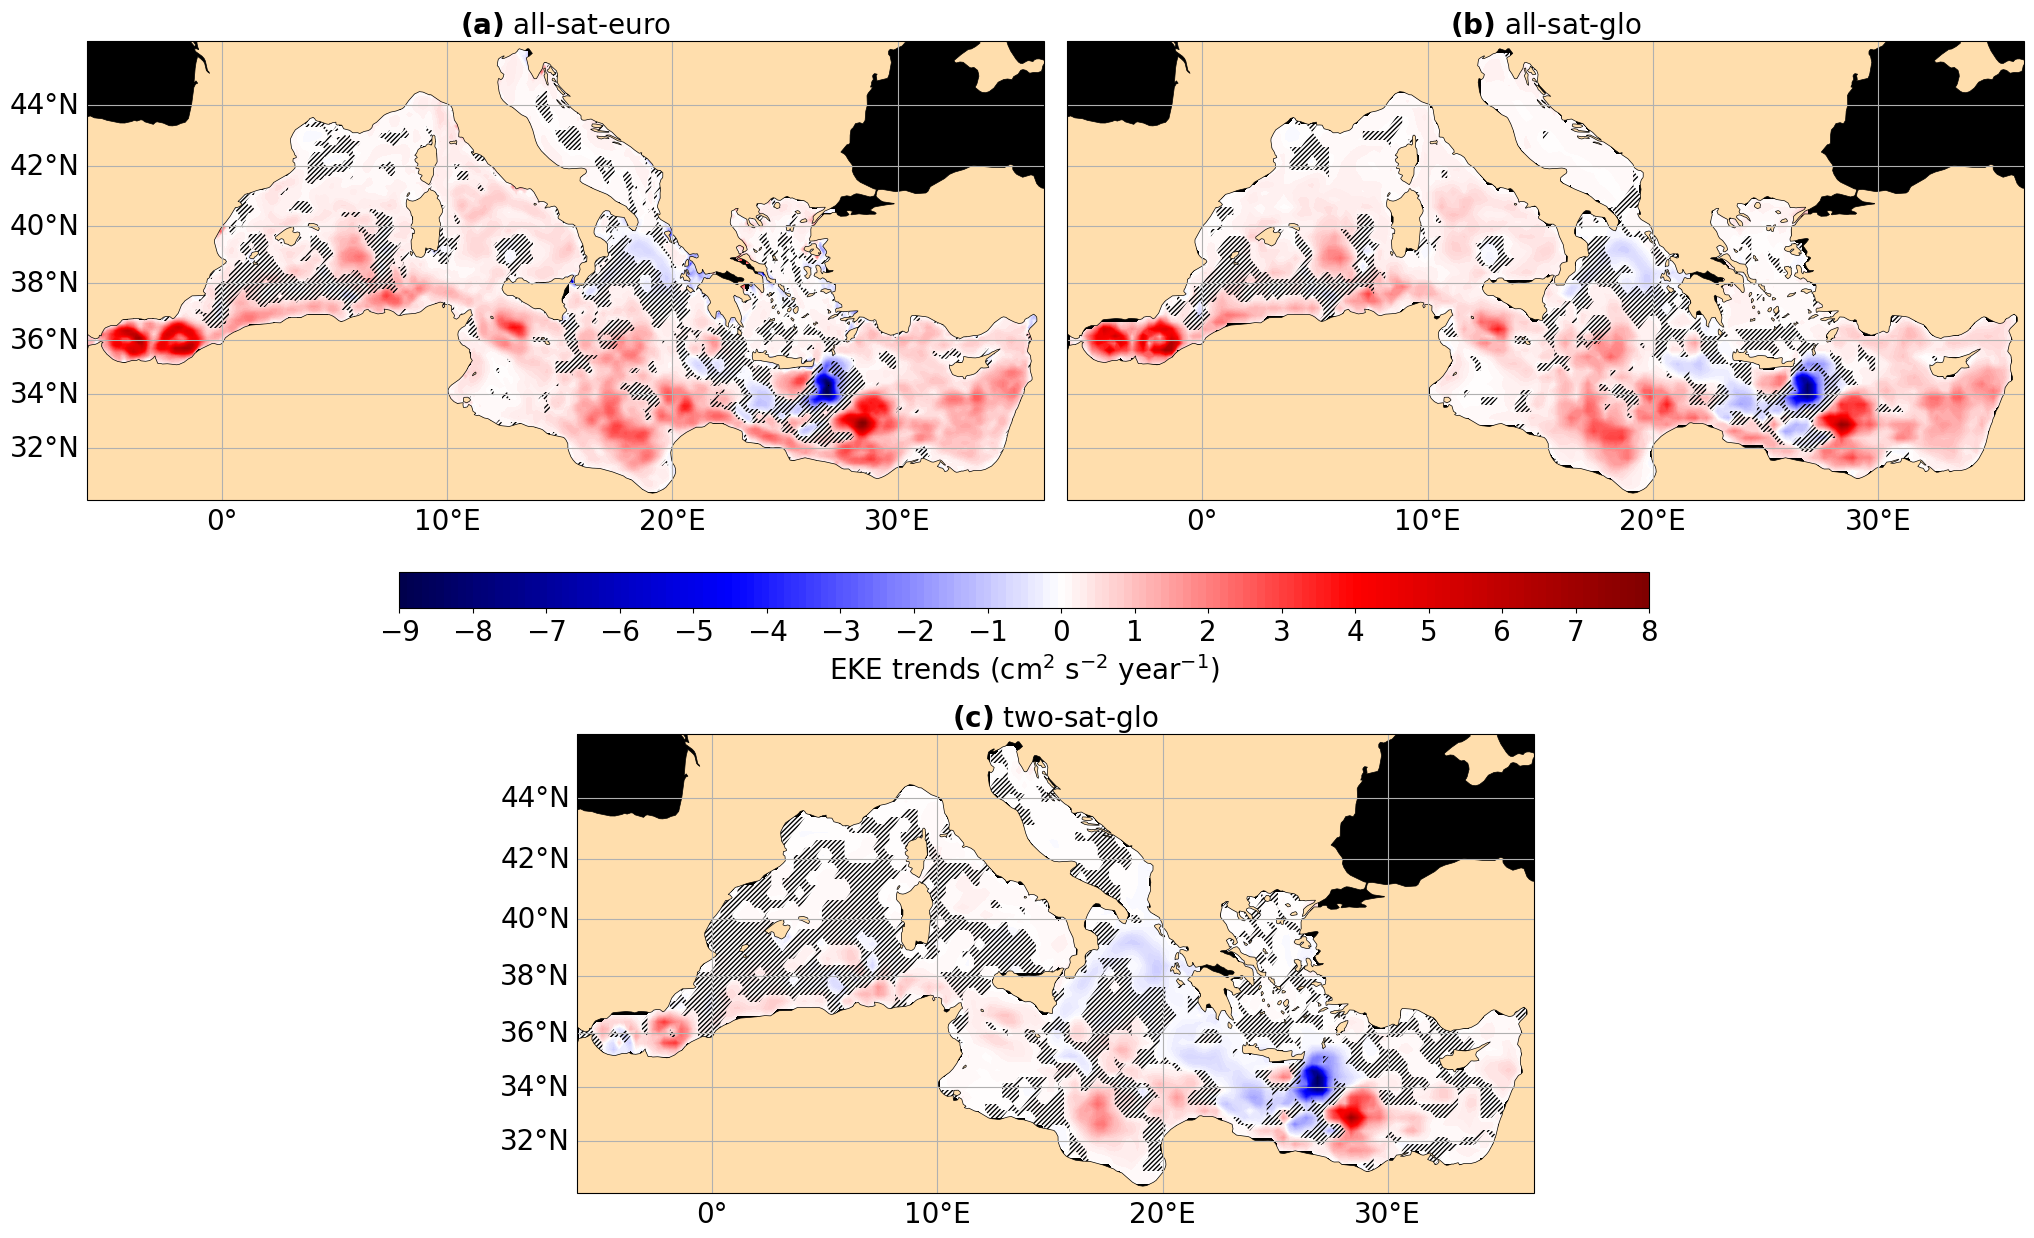

all-sat-euro: 72.3 % of the grid points have a significant trend
all-sat-glo: 71.3 % of the grid points have a significant trend
two-sat-glo: 48.5 % of the grid points have a significant trend


In [10]:
mask_grid = {'AM': masks['MED']['med'], 'AG': masks['MED']['glo'], 'TG': masks['MED']['glo']}

def trend_maps_for(fields, tag):
    out = {}
    for p, da in fields.items():
        out[p] = ea.cached(CACHE / f'trend2d_{tag}_{p}.npy', ea.trend_map,
                           da.where(xr.DataArray(mask_grid[p], dims=('lat', 'lon'),
                                                 coords={'lat': da.lat, 'lon': da.lon})).load(),
                           n_jobs=N_JOBS)
    return out

# trend_maps = trend_maps_for(neke, 'neke')

# Alternative: reuse the maps of the original scripts (stored per day in Redo/*_slpintns.npy)
trend_maps = {'AM': ea.load_legacy_trend_dict(ROOT / 'Redo/AM_MED_slpintns.npy'),
              'AG': ea.load_legacy_trend_dict(ROOT / 'Redo/AG_MED_slpintns.npy'),
              'TG': ea.load_legacy_trend_dict(ROOT / 'Redo/TG_MED_slpintns.npy')}

fig = ef.fig6_trend_maps(trend_maps, {'AM': grid['med'], 'AG': grid['glo'], 'TG': grid['glo']})
save(fig, 'fig06.png'); plt.show()

for p, m in trend_maps.items():
    valid = np.isfinite(m['pvalue'])
    print(f"{ef.PRODUCTS[p][0]}: {100 * np.mean(m['pvalue'][valid] <= ea.ALPHA):.1f} % of the grid points have a significant trend")

## Table 1 — Trends for the different data sets and methods (cm² s⁻² yr⁻¹)

*Mean of all trends*: spatial mean of the gridded trends; *mean of the significant trends*: same, restricted to p ≤ 0.05; *trend of the mean*: trend of the area-weighted Mediterranean mean series (Fig. 3a). First block: anomalies relative to 1993–2023 (this study). Second block (optional, `COMPUTE_CMEMS_TABLE = True`): EKE from the CMEMS velocity anomalies (1993–2012 reference period).

In [11]:
table_neke = ea.trend_table(trend_maps, trends['MED'])
table_neke.index = pd.MultiIndex.from_product([['EKE (1993-2023 anomalies)'], table_neke.index])
display(table_neke.rename(columns={p: ef.PRODUCTS[p][0] for p in ef.PRODUCTS}).round(2))

all-sat-euro  \
EKE (1993-2023 anomalies) Mean of all trends                      0.43   
                          Mean of the significant trends          0.59   
                          Trend of the mean                       0.87   

                                                          all-sat-glo  \
EKE (1993-2023 anomalies) Mean of all trends                     0.38   
                          Mean of the significant trends         0.52   
                          Trend of the mean                      0.75   

                                                          two-sat-glo  
EKE (1993-2023 anomalies) Mean of all trends                     0.06  
                          Mean of the significant trends         0.12  
                          Trend of the mean                      0.06

In [12]:
if COMPUTE_CMEMS_TABLE:
    eke_cmems = {}
    for p, f in EKE_FILES.items():
        da = xr.open_dataset(f)['EKE']
        eke_cmems[p] = da.sel(lat=neke[p].lat, lon=neke[p].lon, method='nearest').assign_coords(
            lat=neke[p].lat, lon=neke[p].lon)       # same domain and grid as NEKE
    maps_cmems = trend_maps_for(eke_cmems, 'eke_cmems')
    trends_cmems = {p: ea.compute_trend(ea.area_weighted_mean(eke_cmems[p], mask_grid[p]).values)
                    for p in eke_cmems}
    table_cmems = ea.trend_table(maps_cmems, trends_cmems)
    table_cmems.index = pd.MultiIndex.from_product([['EKE (CMEMS 1993-2012 reference)'], table_cmems.index])
    display(table_cmems.rename(columns={p: ef.PRODUCTS[p][0] for p in ef.PRODUCTS}).round(2))

## Figure 7 — Gridded versus along-track trends (Alboran Sea and Ierapetra area)

Trend of the across-track EKE (EKE⊥) along reference tracks, from L3 along-track data (`L3-ref`) and from the L4 products sampled at the L3 dates, so that both have the same temporal sampling. The along-track geostrophic velocity is computed from the SLA with a 5-point finite difference; the series are interpolated on a regular 10-day grid and trends are in cm² s⁻² yr⁻¹. The L3 reference missions are TOPEX/Poseidon, Jason-1/2/3 and Sentinel-6A.

Background: gridded `all-sat-glo` trends. **Slow** (cached afterwards).

In [13]:
L3_DIR = DATA / 'eur_L3_008_061' / VERSION / 'processed'
L3_FILES = [L3_DIR / f for f in ['dt_europe_tp_phy_l3_1993_2002.nc',
                                 'dt_europe_j1_phy_l3_2002_2008.nc',
                                 'dt_europe_j2_phy_l3_2008_2016.nc',
                                 'dt_europe_j3_phy_l3_2016_2022.nc',
                                 'dt_europe_s6a_lr_phy_l3_2022_2023.nc']]
L4_DIRS = {'AM': DATA / 'med_allsat_L4_008_068' / VERSION,
           'AG': DATA / 'glo_allsat_L4_008_047' / VERSION,
           'TG': DATA / 'glo_twosat_L4_008_057' / VERSION}
BBOX_ALB = (-6, -1, 35, 37)          # (lon_min, lon_max, lat_min, lat_max)
BBOX_IERA = (26, 29.38, 31, 35.5)

tracks_alb = ea.cached(CACHE / 'along_track_alboran.npy', ea.along_track_trends, L3_FILES, L4_DIRS, BBOX_ALB)
tracks_iera = ea.cached(CACHE / 'along_track_ierapetra.npy', ea.along_track_trends, L3_FILES, L4_DIRS, BBOX_IERA)
print('Alboran tracks:', {k: len(v['lon']) for k, v in tracks_alb.items()})
print('Ierapetra tracks:', {k: len(v['lon']) for k, v in tracks_iera.items()})

KeyboardInterrupt: 

In [ ]:
fig = ef.fig7_along_track(trend_maps['AG'], grid['glo'], tracks_alb, tracks_iera,
                          alb_track='96', iera_tracks=('7', '185'))
save(fig, 'fig07.png'); plt.show()

## Figure 8 — Eddies detected in `all-sat-glo` and `two-sat-glo`

Eddies of the META3.2 DT atlas (Pegliasco et al., 2022) located inside the Mediterranean polygon; the long-lived, short-lived and untracked eddies are all used (no lifetime threshold). Statistics are annual and stop on 31 December 2021; dashed lines are linear fits.

If the merged Mediterranean files do not exist yet they are built from the global atlas and stored in the cache (the raw data folder is not written).

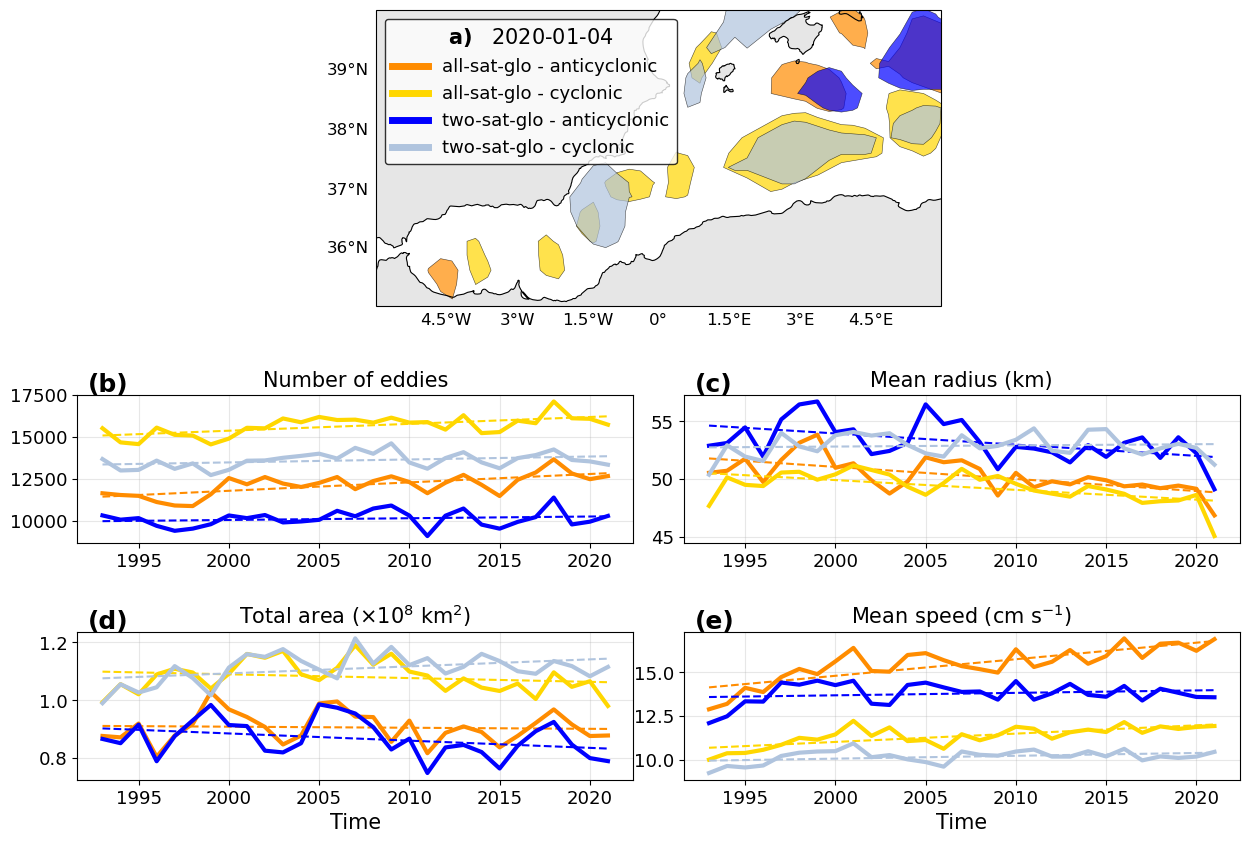

In [14]:
ATLAS = {'AG': DATA / 'eddy_aviso' / 'META3.2_DT_allsat', 'TG': DATA / 'eddy_aviso' / 'META3.2_DT_twosat'}
POLARITY = {'anti': 'Anticyclonic', 'cycl': 'Cyclonic'}

eddies = {(prod, pol): xr.open_dataset(ea.get_med_eddies(src, CACHE / 'eddies' / prod, name))
          for prod, src in ATLAS.items() for pol, name in POLARITY.items()}
eddy_stats = {key: ea.eddy_yearly_stats(ds) for key, ds in eddies.items()}

fig = ef.fig8_eddies(eddies, eddy_stats, date='2020-01-04')
save(fig, 'fig08.png'); plt.show()

## Notes

* Fig. 1: the white arrows (circulation of Atlantic waters, adapted from Millot and Taupier-Letage, 2005) were drawn by hand in the published figure.
* The supplementary figure of the paper (same analysis as Fig. 3 for other regions) can be obtained by adding the corresponding masks to `eke_analysis.MASK_FILES` and calling `fig3_regional_series` with the new regions.
* References: Hargous et al. (2026), *Ocean Sci.* 22, 549–564; Yue and Wang (2004), *Water Resour. Manage.* 18; Pegliasco et al. (2022), *Earth Syst. Sci. Data* 14, 1087–1107.